# Лабораторная работа №2. Pandas и корреляционный анализ

Цель - загрузить табличные данные, изучить пропуски, получить групповые
статистики и исследовать линейную связь признаков с помощью коэффициента Пирсона.

Используются файлы `titanic.csv` и `brainsize.txt` из репозитория. Основные
расчёты реализованы в `pandas_tasks.py` и `correlation_tasks.py`; ноутбук
вызывает эти функции и дополняет результаты графиками и интерпретацией.

Для воспроизведения нужно открыть ноутбук из каталога лабораторной и выполнить
все ячейки сверху вниз. Требуются pandas, numpy, matplotlib и seaborn.
Числа округляются только при выводе; функции возвращают полную точность.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import seaborn as sns

from grader_contracts.pandas_tasks import TitanicInput
from grader_contracts.correlation_tasks import BrainDataInput
from pandas_tasks import analyze_titanic
from correlation_tasks import analyze_brain_correlations

DATA_DIR = Path.cwd()
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
print(f"Python {sys.version.split()[0]}; pandas {pd.__version__}; "
      f"numpy {np.__version__}; matplotlib {plt.matplotlib.__version__}; "
      f"seaborn {sns.__version__}")

Python 3.14.3; pandas 3.1.0; numpy 2.5.4; matplotlib 3.11.2; seaborn 0.13.2


## 1. Titanic: загрузка и пропуски

Пропуски подсчитываются через `isna().sum()` для всех столбцов исходной таблицы.
Условие возраста строгое: `Age > 30`, поэтому ровно 30 лет не учитывается.
Неизвестный возраст не заменяется нулём: при сравнении он не попадает в счётчик,
а при вычислении среднего исключается. Это средний возраст пассажиров с
известным возрастом, а не оценка с заполнением пропусков.

In [2]:
titanic = pd.read_csv(DATA_DIR / "titanic.csv")
titanic_summary = analyze_titanic(TitanicInput(str(DATA_DIR / "titanic.csv")))
missing = pd.DataFrame({"Пропусков": titanic_summary.missing_by_column})
missing["Доля, %"] = 100 * missing["Пропусков"] / titanic_summary.row_count
print(f"Пассажиров: {titanic_summary.row_count}")
print(f"Старше 30 лет: {titanic_summary.adults_over_30_count}")
print(missing.round(2).to_string())

Пассажиров: 891
Старше 30 лет: 305
             Пропусков  Доля, %
PassengerId          0     0.00
Survived             0     0.00
Pclass               0     0.00
Name                 0     0.00
Sex                  0     0.00
Age                177    19.87
SibSp                0     0.00
Parch                0     0.00
Ticket               0     0.00
Fare                 0     0.00
Cabin              687    77.10
Embarked             2     0.22


## 2. Titanic: статистики по классу

После `groupby("Pclass")` среднее по `Age` вычисляется только по известным
возрастам. `Survived` принимает 0 или 1, поэтому его среднее равно доле выживших.
В таблице дополнительно указаны размеры групп и количество известных возрастов.
Пять наибольших тарифов выбираются по убыванию с сохранением повторов:
одинаковую стоимость могли заплатить несколько пассажиров.

In [3]:
class_summary = pd.DataFrame({
    "Пассажиров": titanic.groupby("Pclass").size(),
    "Возраст известен": titanic.groupby("Pclass")["Age"].count(),
    "Средний возраст": pd.Series(titanic_summary.mean_age_by_pclass),
    "Доля выживших": pd.Series(titanic_summary.survival_rate_by_pclass),
})
class_summary.index.name = "Pclass"
print(class_summary.round(4).to_string())
print("Пять наибольших Fare:", titanic_summary.highest_fares)

        Пассажиров  Возраст известен  Средний возраст  Доля выживших
Pclass                                                              
1              216               186          38.2334         0.6296
2              184               173          29.8776         0.4728
3              491               355          25.1406         0.2424
Пять наибольших Fare: [512.3292, 512.3292, 512.3292, 263.0, 263.0]


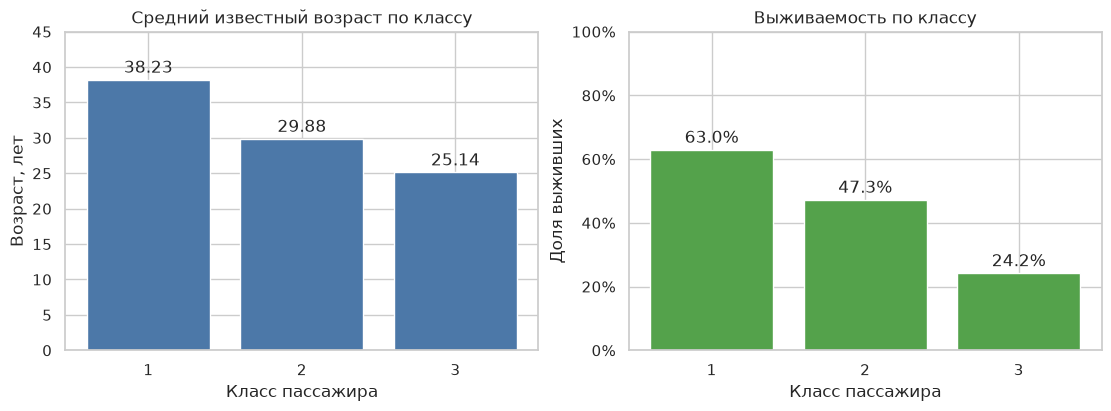

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
labels = [str(pclass) for pclass in class_summary.index]
axes[0].bar(labels, class_summary["Средний возраст"], color="#4C78A8")
axes[0].set(xlabel="Класс пассажира", ylabel="Возраст, лет",
            title="Средний известный возраст по классу", ylim=(0, 45))
axes[1].bar(labels, class_summary["Доля выживших"], color="#54A24B")
axes[1].set(xlabel="Класс пассажира", ylabel="Доля выживших",
            title="Выживаемость по классу", ylim=(0, 1))
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
for axis, values, pattern in [
    (axes[0], class_summary["Средний возраст"], "{:.2f}"),
    (axes[1], class_summary["Доля выживших"], "{:.1%}"),
]:
    for bar, value in zip(axis.patches, values):
        axis.annotate(pattern.format(value),
                      (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                      xytext=(0, 5), textcoords="offset points", ha="center")
plt.show()

В таблице 891 пассажир; у 305 известный возраст превышает 30 лет.
Пропущены 177 значений возраста (19,87%), 687 значений `Cabin` (77,10%) и
2 значения `Embarked` (0,22%). В остальных столбцах пропусков нет.

Средний известный возраст уменьшается от первого класса к третьему:
38,23; 29,88; 25,14 года. Доли выживших составляют 62,96%; 47,28%; 24,24%.
Эти различия описывают выборку и сами по себе не доказывают причинное влияние
класса: группы отличаются и по другим признакам. Из-за пропусков возраста
его групповые средние следует интерпретировать с осторожностью.

Пять наибольших тарифов: 512,3292; 512,3292; 512,3292; 263,0; 263,0.

## 3. Данные brainsize и метод корреляции

Таблица читается с разделителем tab (`sep="\t"`); `NA` распознаётся как пропуск.
Наблюдения разделяются по `Gender`, затем внутри каждой группы считаются связи
`FSIQ`, `VIQ`, `PIQ`, `Weight`, `Height` с `MRI_Count`.

Коэффициент Пирсона для каждой пары признаков:

\[
r_{xy} = \frac{\sum_i(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_i(x_i-\bar{x})^2\sum_i(y_i-\bar{y})^2}}.
\]

Он лежит в диапазоне от −1 до 1 и характеризует направление и силу линейной
связи. Каждая корреляция использует строки, в которых известны оба значения
данной пары. Строки с пропуском `Weight` не исключаются из расчётов `FSIQ`,
`VIQ` или `PIQ`. При постоянном признаке или менее двух пар корреляция
не определена (`NaN`); такие значения не участвуют в выборе максимума.

In [5]:
brain = pd.read_csv(DATA_DIR / "brainsize.txt", sep="\t", na_values=["NA"])
brain_summary = analyze_brain_correlations(BrainDataInput(str(DATA_DIR / "brainsize.txt")))
features = ["FSIQ", "VIQ", "PIQ", "Weight", "Height"]
numeric_features = features + ["MRI_Count"]
groups = {
    "Женщины": brain.loc[brain["Gender"] == "Female"],
    "Мужчины": brain.loc[brain["Gender"] == "Male"],
}
print(f"Всего: {len(brain)}; женщин: {brain_summary.women_count}; "
      f"мужчин: {brain_summary.men_count}")
print("Пропуски по группам:")
print(pd.DataFrame({name: group[numeric_features].isna().sum()
                    for name, group in groups.items()}).to_string())

Всего: 40; женщин: 20; мужчин: 20
Пропуски по группам:
           Женщины  Мужчины
FSIQ             0        0
VIQ              0        0
PIQ              0        0
Weight           0        2
Height           0        1
MRI_Count        0        0


In [6]:
correlations = pd.DataFrame({
    "Женщины": brain_summary.women_mri_correlation,
    "Мужчины": brain_summary.men_mri_correlation,
}).reindex(features)
pair_counts = pd.DataFrame({
    name: {feature: len(group[[feature, "MRI_Count"]].dropna())
           for feature in features}
    for name, group in groups.items()
})
print("Корреляции с MRI_Count:")
print(correlations.round(6).to_string())
print("\nЧисло полных пар для каждого коэффициента:")
print(pair_counts.to_string())
print("\nПризнак с наибольшим |r| среди обеих групп:",
      brain_summary.strongest_mri_feature)

Корреляции с MRI_Count:
         Женщины   Мужчины
FSIQ    0.325697  0.498369
VIQ     0.254933  0.413105
PIQ     0.396157  0.568237
Weight  0.446271 -0.076875
Height  0.174541  0.301543

Число полных пар для каждого коэффициента:
        Женщины  Мужчины
FSIQ         20       20
VIQ          20       20
PIQ          20       20
Weight       20       18
Height       20       19

Признак с наибольшим |r| среди обеих групп: PIQ


## 4. Диаграммы рассеяния

Каждая точка соответствует одному наблюдению с известными значениями обоих
признаков. Женщины и мужчины показаны в разных строках, чтобы видеть различия
внутри групп. Шкала `MRI_Count` общая; в заголовке каждой панели указаны
коэффициент Пирсона и число использованных пар.

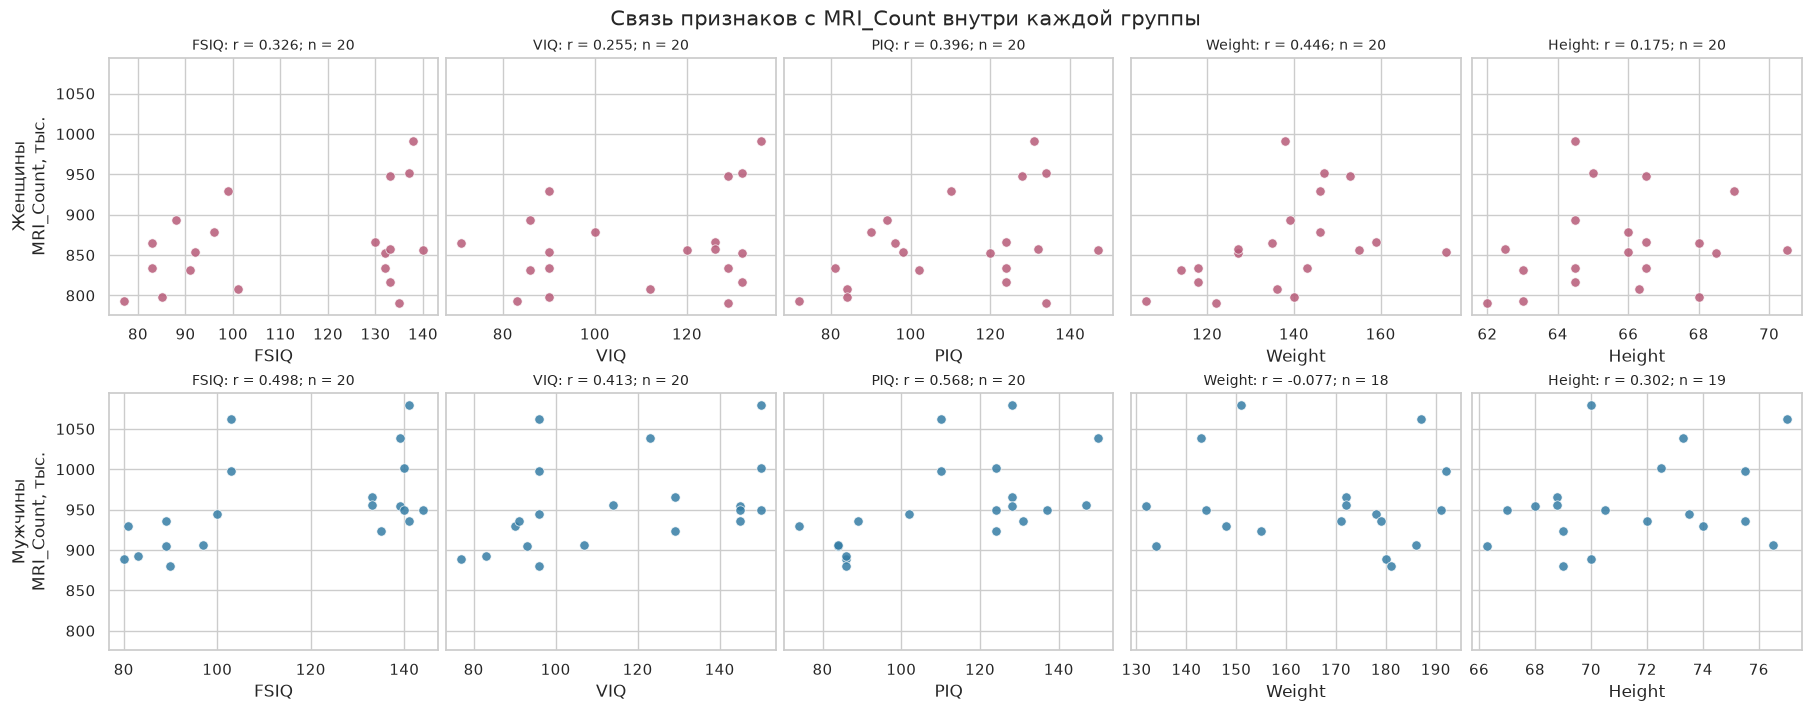

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharey=True, layout="constrained")
colors = {"Женщины": "#B65A78", "Мужчины": "#357DA5"}
for row, (name, group) in enumerate(groups.items()):
    for column, feature in enumerate(features):
        axis = axes[row, column]
        pairs = group[[feature, "MRI_Count"]].dropna()
        sns.scatterplot(data=pairs, x=feature, y="MRI_Count", ax=axis,
                        color=colors[name], s=45, alpha=0.85, edgecolor="white")
        r = correlations.loc[feature, name]
        axis.set_title(f"{feature}: r = {r:.3f}; n = {len(pairs)}", fontsize=10)
        axis.set_ylabel(f"{name}\nMRI_Count, тыс." if column == 0 else "")
        axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1000:.0f}"))
fig.suptitle("Связь признаков с MRI_Count внутри каждой группы", fontsize=15)
plt.show()

## 5. Тепловые карты корреляций

Для каждой группы показана полная матрица шести числовых признаков. Единая
цветовая шкала от −1 до 1 позволяет сравнивать панели. Диагональ равна 1,
поскольку это корреляция признака с самим собой; при поиске самого связанного
с `MRI_Count` признака диагональ исключена.

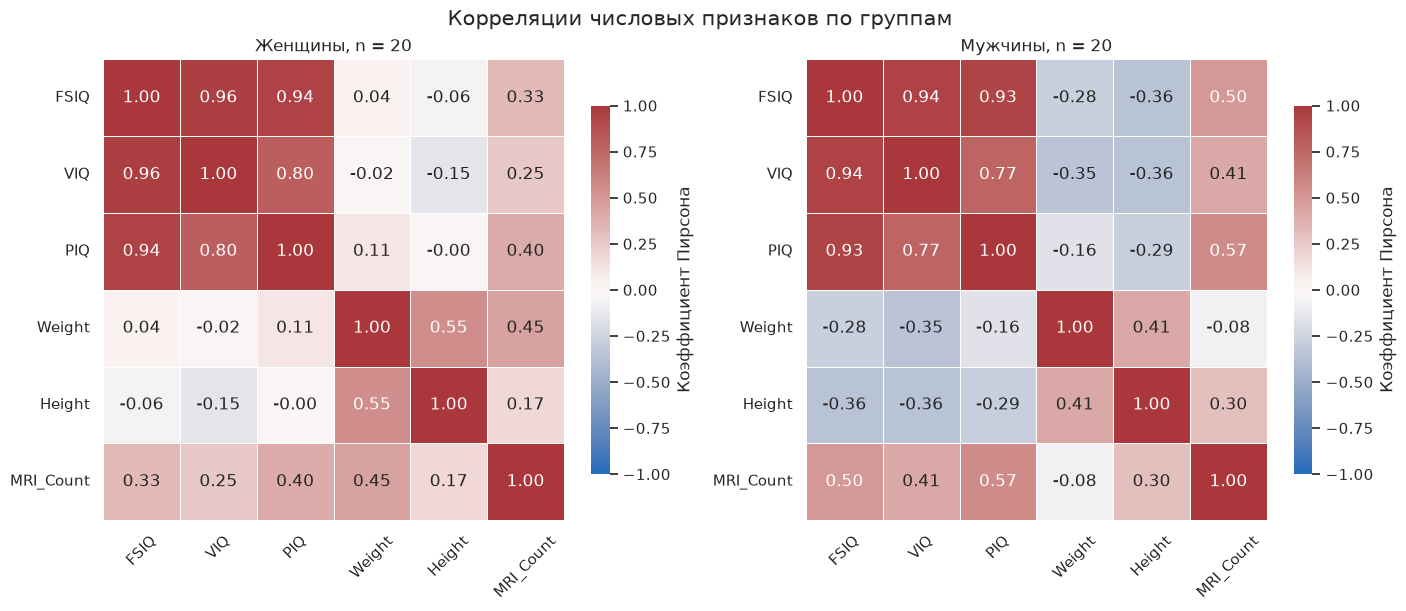

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
for axis, (name, group) in zip(axes, groups.items()):
    matrix = group[numeric_features].corr(method="pearson")
    np.testing.assert_allclose(matrix.loc[features, "MRI_Count"], correlations[name])
    sns.heatmap(matrix, ax=axis, vmin=-1, vmax=1, center=0, cmap="vlag",
                annot=True, fmt=".2f", square=True, linewidths=0.5,
                cbar_kws={"label": "Коэффициент Пирсона", "shrink": 0.8})
    axis.set_title(f"{name}, n = {len(group)}")
    axis.tick_params(axis="x", rotation=45)
    axis.tick_params(axis="y", rotation=0)
fig.suptitle("Корреляции числовых признаков по группам", fontsize=15)
plt.show()

## 6. Интерпретация и выводы

В `brainsize.txt` 40 наблюдений: по 20 мужчин и женщин. У мужчин отсутствуют
два значения `Weight` и одно `Height`, поэтому их корреляции рассчитаны по
18 и 19 парам соответственно. Для остальных пар используются 20 наблюдений.

Наибольший модуль корреляции с `MRI_Count` среди обеих групп у **PIQ у мужчин**:
**r = 0,568237**. Это положительная линейная связь: в этой группе большим
значениям PIQ в среднем соответствуют большие значения MRI_Count.
У женщин самая большая по модулю связь наблюдается для **Weight**:
**r = 0,446271**; корреляция PIQ с MRI_Count равна 0,396157.

Все три IQ-показателя положительно коррелируют с MRI_Count в обеих группах.
Для Weight у мужчин r = −0,076875: выраженная линейная связь в этой выборке
не наблюдается. Отсутствие линейной корреляции не исключает нелинейную связь.
На тепловых картах видны также положительные связи между IQ-показателями,
поэтому их нельзя считать независимыми друг от друга.

Коэффициенты описывают небольшую выборку, чувствительны к отдельным наблюдениям
и не доказывают причинность. Максимум выбран среди десяти коэффициентов;
сам по себе такой выбор не является проверкой статистической значимости.
Различия корреляций между мужчинами и женщинами здесь не проверялись на
значимость и не дают основания делать выводы обо всей популяции.

Таким образом, выполнены загрузка и группировка данных, подсчёт пропусков,
расчёт агрегатов и корреляций. Диаграммы рассеяния дополняют численные
коэффициенты, а тепловые карты показывают структуру линейных связей.

## 7. Проверка реализации

Команда `python -m unittest -v` из каталога лабораторной запускает проверки
в `test_tasks.py`. Они охватывают исходные данные, пропуски, строгую границу
возраста, повторяющиеся тарифы, короткие таблицы и отрицательную корреляцию.
Корреляции дополнительно сопоставляются с независимым расчётом по формуле
Пирсона из стандартной библиотеки. Это проверяет использование полных пар,
а не общее удаление всех строк с пропусками.